# Data Generation Master

One-shot generation of the stochastic demand-capacity scenarios used by the L-shaped and deterministic equivalent models. Every capacity scenario is paired with every demand scenario, giving **7 capacity x `N_DEMAND_SCENARIOS` demand** scenario pairs.

## Instructions

1. Check that the input files below are in `data/` (relative to this notebook).
2. In **Settings**, set `N_DEMAND_SCENARIOS` (and, if needed, the other settings in the table below).
3. Run all cells top to bottom (*Run All*). The last cell prints the number of pairs created, e.g. `35 scenario pairs = 7 capacity x 5 demand`.
4. In the Julia driver (`../vaccine_tender_L_shaped.jl`), set the demand and capacity scenario counts in the call at the bottom of the file to `N_DEMAND_SCENARIOS` and `7`, e.g. `tender_stochastic_L_shaped(10,5,5,7,...)`. If the product is smaller than the number of pairs, the model only uses a subset.

Re-running with the same settings and `SEED` reproduces the same scenarios. All outputs are overwritten on each run.

## Inputs

| File (in `data/`) | Used in | Contents |
|---|---|---|
| `production_capacity_scenarios_15YR_applied.xlsx` | Step 1 | One sheet per capacity scenario (`base_capacity`, `IPV_Shortage`, `pandemic`, `funding_delay`, `innacurate_forecast`, `supply_chain`, `other`). Each sheet: `Manufacturer` column plus yearly capacity columns `1`-`15`. |
| `Medium_Demand_Structured_15YR.csv` | Step 2 | Current 15-year baseline demand per antigen (`antigen`, `demand` list of 15 values, `probability`, `demand_SID`). The demand forecast replicates this in expectation. |
| `Demand_Scenarios_Base.xlsx` | Step 2 | Sheet `total_capacity_calcs`: historical doses by vaccine and World Bank income group, 2000-2030. Used only to estimate demand variability (2008-2023 by default). |

## Settings

| Setting | Default | Meaning |
|---|---|---|
| `N_DEMAND_SCENARIOS` | `5` | Number of demand draws; total pairs = 7 x `N_DEMAND_SCENARIOS`. |
| `SEED` | `9` | Random seed for the demand draws. |
| `ANTIGENS` | all 12 antigens (incl. Measles, Mumps, Rubella from M, MR, MMR) | Antigens kept in the scenario pairs. Must cover the antigens in the Julia model's `A` (`create_vaccine_data.jl`). |
| `N_YEARS` | `15` | Planning horizon (years); must match the baseline and capacity files. |
| `capacity_scenario_names` / `capacity_scenario_probs` | 7 scenarios | Capacity sheets to read and their probabilities. |
| `HIST_START`, `HIST_END` | `2008`, `2023` | Historical years used to estimate demand uncertainty. |
| `TREND_WINDOW` | `5` | Centered moving-average window (years) for the historical trend. |
| `FIX_FIRST_YEAR` | `True` | Year 1 is the known current year and stays at the baseline in every draw. |
| `MODEL_DATA_DIR` | `../data` | Folder the Julia model reads from; the model inputs are copied there. |

## Steps

1. **Reformat the capacity scenarios**: stack the capacity sheets into one table with each manufacturer's 15-year capacity as a list.
2. **Forecast demand**: draw `N_DEMAND_SCENARIOS` demand scenarios centered on the baseline.
   - Antigen-level history is built by adding each vaccine's doses to every antigen it covers (e.g. `DTwP-HepB-Hib` counts toward Diphtheria, Tetanus, Pertussis, Hepatitis_B and Hib).
   - Per antigen, the variability of log demand is estimated from history: AR(1) year-to-year noise around a moving-average trend, a random walk on the trend (its step size is the historical variability of trend growth, so the forecast fans out over the horizon), and the correlation between antigens.
   - Draws: `D[a,t] = base[a,t] * exp(RW[a,t] + AR[a,t] - var[a,t]/2)`; the `-var/2` term keeps the average draw equal to the baseline. Each draw has probability `1/N_DEMAND_SCENARIOS`.
   - History is only used for relative (log) variability; its levels are global demand, while the baseline is the model's demand.
   - A check prints the gap between the mean of 20,000 draws and the baseline, and the coefficient of variation by year; a plot shows the draws, a 90% band and the baseline for each antigen.
3. **Create the scenario pairs**: full cross product of capacity x demand scenarios. Pair probability = capacity probability x demand probability, normalized to sum to 1.
4. **Build the scenario pair dictionary**: `{pair: {"demand": {year: {antigen: value}}, "capacity": {year: {manufacturer: value}}}}`.
5. **Save the pair probabilities** and copy the model inputs to `MODEL_DATA_DIR`.

## Outputs

| File | Location | Contents |
|---|---|---|
| `production_capacity_scenarios_15YR_applied.csv` | `data/` | Reformatted capacity scenarios (`manufacturer`, `capacity_scenario`, `capacity_scenario_probability`, `capacity` list). |
| `antigen_demand_forecast_scenario.csv` | `data/` | Demand draws in the `antigen_demand_80_20_5_scenarios` format (`antigen`, `demands` list of 15 integers, `prob`, `demand_SID`). |
| `pair_demand_capacity_15YR_stoch.csv` / `.json` | `data/` | Long table of the pairs (`unit`, `values`, `type`, `pair_idx`, `pair`, `pair_probability`). |
| `scenario_pairs_new_15YR_stoch.json` | `data/` and `MODEL_DATA_DIR` | Scenario pair dictionary read by the model (`d_real_tilde`, `s_real_tilde`). |
| `scenario_pair_probabilities_new_15YR_stoch.json` | `data/` and `MODEL_DATA_DIR` | Pair probabilities read by the model (`p_ω`). |

## Requirements

Python with `pandas`, `numpy`, `matplotlib`, `openpyxl` (Excel reading), `loguru`, `tabulate` and `joblib`.

In [2]:
import sys, os, glob, time, socket
import json
from loguru import logger
from tabulate import tabulate
import pandas as pd
import numpy as np
import joblib
import random
import shutil
import matplotlib.pyplot as plt

## Settings

In [3]:
# ANTIGENS = [
#     "Diphtheria",
#     "Pertussis",
#     "Polio",
#     "Tetanus",
#     "Rotavirus",
#     "PCV",
#     "Measles",
#     "Mumps",
#     "Rubella",
#     "Hepatitis_B",
#     "Hib",
#     "HPV",
# ]

ANTIGENS = [
    "Measles",
    "Mumps",
    "Rubella",
    "Diphtheria",
    "Pertussis",
    "Polio",
    "Tetanus",
    "Rotavirus",
    "PCV",
    "Hepatitis_B",
    "Hib",
    "HPV",
]

N_YEARS = 15
YEARS = np.arange(1, N_YEARS + 1)

# Demand forecast (Step 2)
N_DEMAND_SCENARIOS = 5       # number of demand draws -> total scenario pairs = 7 capacity x N_DEMAND_SCENARIOS
SEED = 9                     # random seed for the demand draws
HIST_START, HIST_END = 2008, 2023   # historical years used to estimate demand uncertainty
TREND_WINDOW = 5             # centered moving-average window (years) for the historical trend
FIX_FIRST_YEAR = True        # year 1 is the known current year -> no uncertainty

BASELINE_FILE = "data/Medium_Demand_Structured_15YR.csv"
HISTORY_FILE = "data/Demand_Scenarios_Base.xlsx"
DEMAND_FORECAST_FILE = "data/antigen_demand_forecast_scenario.csv"

# Copy the model input files to the folder the Julia model reads from
MODEL_DATA_DIR = "../data"

In [4]:
# capacity_scenario_names = [
#     "base_capacity",
#     "pandemic",
# ]
# capacity_scenario_probs = {
#     "base_capacity": 0.8418,
#     "pandemic": 0.0275,
# }

capacity_scenario_names = [
    "base_capacity",
    "IPV_Shortage",
    "pandemic",
    "funding_delay",
    "innacurate_forecast",
    "supply_chain",
    "other",
]
capacity_scenario_probs = {
    "base_capacity": 0.8418,
    "IPV_Shortage": 0.0173,
    "pandemic": 0.0275,
    "funding_delay": 0.0778,
    "innacurate_forecast": 0.0023,
    "supply_chain": 0.0058,
    "other": 0.0275,
}

# capacity_scenario_names = [
#     "base_capacity"
# ]
# capacity_scenario_probs = {
#     "base_capacity": 1
# }

## Step 1: Reformat the capacity scenarios

In [5]:
dfs = []
for scenario in capacity_scenario_names:
    temp = pd.read_excel(
        f"data/production_capacity_scenarios_15YR_applied.xlsx",
        sheet_name=scenario,
    )
    temp["capacity_scenario"] = scenario
    temp["capacity_scenario_probability"] = capacity_scenario_probs[scenario]
    dfs.append(temp)

print(temp)
# Concatenate all the dataframes
capacity_scenarios = pd.concat(dfs, ignore_index=True)
# rename the columns
capacity_scenarios.rename(columns={"Manufacturer": "manufacturer"}, inplace=True)
# Convert years to columns
capacity_scenarios["capacity"] = capacity_scenarios[YEARS].values.tolist()
# Drop the years columns
capacity_scenarios.drop(YEARS, axis=1, inplace=True)

capacity_scenarios.to_csv("data/production_capacity_scenarios_15YR_applied.csv", index=False)

       Manufacturer  ...  capacity_scenario_probability
0       AJ_Vaccines  ...                         0.0275
1          BB_NCIPD  ...                         0.0275
2    Bharat_Biotech  ...                         0.0275
3         Bilthoven  ...                         0.0275
4      Biological_E  ...                         0.0275
5    China_National  ...                         0.0275
6               GSK  ...                         0.0275
7      Haffkine_Bio  ...                         0.0275
8           LG_Chem  ...                         0.0275
9       Merck_Sharp  ...                         0.0275
10           PT_Bio  ...                         0.0275
11   Panacea_Biotec  ...                         0.0275
12           Pfizer  ...                         0.0275
13           Sanofi  ...                         0.0275
14  Serum_Institute  ...                         0.0275

[15 rows x 18 columns]


In [6]:
capacity_scenarios

,manufacturer,capacity_scenario,capacity_scenario_probability,capacity
0,Serum_Institute,base_capacity,0.8418,"[5201000.0, 7140000.0, 8329999.999999999, 8329..."
1,GSK,base_capacity,0.8418,"[26400000.0, 20460000.0, 20740000.0, 28500000...."
2,Biological_E,base_capacity,0.8418,"[52270000.0, 57939999.99999999, 58989999.99999..."
3,Haffkine_Bio,base_capacity,0.8418,"[8119999.999999999, 11130000.0, 13020000.0, 12..."
4,Panacea_Biotec,base_capacity,0.8418,"[96900000.0, 110200000.0, 111600000.0, 1053000..."
...,...,...,...,...
100,PT_Bio,other,0.0275,"[53364779.6951938, 65600000.0, 74700000.0, 729..."
101,Panacea_Biotec,other,0.0275,"[96900000.0, 110200000.0, 111600000.0, 1053000..."
102,Pfizer,other,0.0275,"[55510000.0, 63349999.99999999, 65799999.99999..."
103,Sanofi,other,0.0275,"[9730000.0, 10640000.0, 10402228.06457212, 110..."


## Step 2: Forecast demand scenarios

Builds a stochastic demand forecast that replicates the current 15-year baseline and draws `N_DEMAND_SCENARIOS` scenarios from it.

1. Antigen-level demand history from `Demand_Scenarios_Base.xlsx` (`total_capacity_calcs`): each vaccine's doses are added to every antigen it covers (e.g. `DTwP-HepB-Hib` counts toward Diphtheria, Tetanus, Pertussis, Hepatitis_B and Hib).
2. Per antigen, from the historical years, estimate the uncertainty in log demand:
   - **Year-to-year noise**: AR(1) deviations around a centered moving average (`sigma`, `phi`).
   - **Trend uncertainty**: standard deviation of the yearly trend growth rate (`sigma_growth`), used as a random walk so the forecast fans out over the horizon.
   - **Cross-antigen correlation** of the noise (antigens in combination vaccines move together).
3. Simulate `log D[a,t] = log base[a,t] + RW[a,t] + AR[a,t] - var[a,t]/2`. The `-var/2` term keeps the mean of the draws equal to the baseline. Year 1 is the known current year and stays at the baseline.

History is only used for the *relative* (log) variability: its levels are global demand, while the baseline is the model's demand. Draws have equal probability `1/N_DEMAND_SCENARIOS`.

### 2a: Baseline (current data)

In [7]:
baseline_df = pd.read_csv(BASELINE_FILE, converters={"demand": pd.eval})
FORECAST_ANTIGENS = baseline_df["antigen"].tolist()
baseline = pd.DataFrame(baseline_df["demand"].tolist(), index=FORECAST_ANTIGENS).astype(float)
baseline.columns = range(1, baseline.shape[1] + 1)
assert baseline.shape[1] == N_YEARS, f"baseline has {baseline.shape[1]} years, expected {N_YEARS}"
print(f"{len(FORECAST_ANTIGENS)} antigens x {N_YEARS} years")
(baseline / 1e6).round(1)

12 antigens x 15 years


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Measles,346.1,377.6,407.5,271.5,386.6,290.5,326.8,309.7,355.2,404.5,345.9,345.6,345.3,345.0,344.7
Mumps,276.9,291.3,386.5,259.1,385.7,289.6,325.9,319.4,304.4,374.6,346.0,350.5,355.0,359.5,363.9
Rubella,251.6,267.8,370.3,240.4,376.8,278.9,312.9,283.9,256.6,271.6,284.1,282.8,281.5,280.2,279.0
Diphtheria,570.6,619.5,626.5,594.5,596.0,587.1,593.1,588.2,595.0,600.5,593.5,592.9,592.2,591.6,590.9
Tetanus,577.7,626.4,633.3,601.3,598.9,590.0,596.1,591.3,598.1,603.5,595.0,593.8,592.5,591.3,590.1
Pertussis,320.7,347.4,352.5,336.0,334.9,328.0,331.2,328.6,331.8,334.6,330.4,329.7,328.9,328.1,327.4
Hepatitis_B,59.5,66.8,70.9,67.1,66.3,64.6,65.5,64.1,64.9,65.3,65.4,65.4,65.4,65.4,65.3
Hib,522.2,582.2,608.6,590.7,591.7,572.5,130.8,128.8,131.1,133.3,135.5,137.7,139.9,142.2,144.4
Polio,522.2,582.2,608.6,590.7,591.7,572.5,151.4,215.2,243.4,251.4,121.7,189.6,187.3,185.0,182.7
HPV,19.0,18.8,27.5,72.8,92.7,64.7,42.2,42.4,33.7,35.0,51.7,52.9,54.1,55.4,56.6


### 2b: Antigen-level demand history

In [8]:
raw = pd.read_excel(HISTORY_FILE, sheet_name="total_capacity_calcs", header=None)

# demand block = rows from the header down to the first blank row (capacity calcs follow it)
end = raw.index[raw[1].isna()][0]
hist_raw = raw.iloc[1:end].copy()
hist_raw.columns = ["_", "vaccine", "wb_status"] + [int(y) for y in raw.iloc[0, 3:]]
years = [c for c in hist_raw.columns if isinstance(c, int)]
vaccine_hist = hist_raw.groupby("vaccine")[years].sum(min_count=1)   # sum over income groups

def vaccine_antigens(vaccine):
    """Antigens covered by a vaccine (combination vaccines are split on '-')."""
    antigens = set()
    if vaccine in ("Measles", "MR", "MM", "MMR", "MMRV"):
        antigens.add("Measles")
    if vaccine in ("Mumps", "MM", "MMR", "MMRV"):
        antigens.add("Mumps")
    if vaccine in ("Rubella", "MR", "MMR", "MMRV"):
        antigens.add("Rubella")
    for part in vaccine.split("-"):
        if part in ("Diphtheria", "DT", "Td", "Tdap", "DTaP", "DTwP"):
            antigens |= {"Diphtheria", "Tetanus"}
        if part == "TT":
            antigens.add("Tetanus")
        if part in ("Tdap", "DTaP", "DTwP"):
            antigens.add("Pertussis")
        if part == "HepB":
            antigens.add("Hepatitis_B")
        if part == "Hib":
            antigens.add("Hib")
        if part in ("IPV", "bOPV", "tOPV"):
            antigens.add("Polio")
        if part == "HPV":
            antigens.add("HPV")
        if part == "Rota":
            antigens.add("Rotavirus")
        if part == "PCV":
            antigens.add("PCV")
    return antigens

antigen_vaccines = {a: [v for v in vaccine_hist.index if a in vaccine_antigens(v)] for a in FORECAST_ANTIGENS}
for a, vs in antigen_vaccines.items():
    print(f"{a:12s}: {vs}")

history = pd.DataFrame({a: vaccine_hist.loc[vs].sum(min_count=1) for a, vs in antigen_vaccines.items()}).T
history = history.loc[FORECAST_ANTIGENS, HIST_START:HIST_END]
(history / 1e6).round(0)

Measles     : ['MM', 'MMR', 'MMRV', 'MR', 'Measles']
Mumps       : ['MM', 'MMR', 'MMRV', 'Mumps']
Rubella     : ['MMR', 'MMRV', 'MR', 'Rubella']
Diphtheria  : ['DT', 'DTaP', 'DTaP-HepB', 'DTaP-HepB-Hib', 'DTaP-HepB-Hib-IPV', 'DTaP-HepB-IPV', 'DTaP-Hib', 'DTaP-Hib-IPV', 'DTaP-IPV', 'DTwP', 'DTwP-HepB', 'DTwP-HepB-Hib', 'DTwP-Hib', 'Diphtheria', 'Td', 'Td-IPV', 'Tdap', 'Tdap-IPV']
Tetanus     : ['DT', 'DTaP', 'DTaP-HepB', 'DTaP-HepB-Hib', 'DTaP-HepB-Hib-IPV', 'DTaP-HepB-IPV', 'DTaP-Hib', 'DTaP-Hib-IPV', 'DTaP-IPV', 'DTwP', 'DTwP-HepB', 'DTwP-HepB-Hib', 'DTwP-Hib', 'Diphtheria', 'TT', 'Td', 'Td-IPV', 'Tdap', 'Tdap-IPV']
Pertussis   : ['DTaP', 'DTaP-HepB', 'DTaP-HepB-Hib', 'DTaP-HepB-Hib-IPV', 'DTaP-HepB-IPV', 'DTaP-Hib', 'DTaP-Hib-IPV', 'DTaP-IPV', 'DTwP', 'DTwP-HepB', 'DTwP-HepB-Hib', 'DTwP-Hib', 'Tdap', 'Tdap-IPV']
Hepatitis_B : ['DTaP-HepB', 'DTaP-HepB-Hib', 'DTaP-HepB-Hib-IPV', 'DTaP-HepB-IPV', 'DTwP-HepB', 'DTwP-HepB-Hib', 'HepB']
Hib         : ['DTaP-HepB-Hib', 'DTaP-HepB-Hib-IPV', 

,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Measles,234.0,228.0,249.0,274.0,259.0,292.0,304.0,465.0,440.0,499.0,744.0,592.0,444.0,559.0,477.0,489.0
Mumps,87.0,89.0,94.0,98.0,99.0,99.0,118.0,108.0,102.0,104.0,146.0,106.0,115.0,112.0,118.0,109.0
Rubella,110.0,114.0,119.0,122.0,126.0,137.0,169.0,241.0,234.0,293.0,587.0,464.0,361.0,485.0,366.0,393.0
Diphtheria,660.0,672.0,674.0,689.0,689.0,683.0,699.0,706.0,748.0,769.0,808.0,905.0,910.0,892.0,895.0,903.0
Tetanus,766.0,783.0,787.0,832.0,846.0,857.0,883.0,894.0,908.0,967.0,981.0,955.0,927.0,906.0,909.0,916.0
Pertussis,548.0,560.0,563.0,573.0,574.0,575.0,579.0,582.0,581.0,587.0,589.0,580.0,558.0,547.0,549.0,553.0
Hepatitis_B,382.0,399.0,397.0,454.0,488.0,492.0,497.0,500.0,505.0,516.0,519.0,515.0,498.0,488.0,493.0,503.0
Hib,180.0,242.0,248.0,255.0,283.0,295.0,320.0,384.0,408.0,412.0,417.0,414.0,399.0,394.0,398.0,402.0
Polio,490.0,509.0,513.0,540.0,574.0,591.0,604.0,643.0,754.0,820.0,789.0,801.0,780.0,775.0,802.0,828.0
HPV,9.0,10.0,11.0,13.0,19.0,20.0,24.0,25.0,27.0,30.0,32.0,36.0,41.0,50.0,50.0,58.0


### 2c: Estimate the uncertainty

In [9]:
log_hist = np.log(history)
trend = log_hist.T.rolling(TREND_WINDOW, center=True, min_periods=3).mean().T
resid = log_hist - trend                      # year-to-year noise around the trend
growth = trend.diff(axis=1).iloc[:, 1:]       # yearly trend growth rate

params = pd.DataFrame({
    "sigma": resid.std(axis=1),
    # moving-average detrending biases phi downward; negative persistence is not meaningful here
    "phi": resid.apply(lambda r: r.autocorr(1), axis=1).clip(0.0, 0.9),
    "sigma_growth": growth.std(axis=1),
})

# cross-antigen correlation of the noise, repaired to be positive semi-definite
corr = resid.T.corr().loc[FORECAST_ANTIGENS, FORECAST_ANTIGENS].values
eigval, eigvec = np.linalg.eigh(corr)
corr = eigvec @ np.diag(np.clip(eigval, 1e-6, None)) @ eigvec.T
d = np.sqrt(np.diag(corr))
corr = corr / np.outer(d, d)
chol = np.linalg.cholesky(corr)

params.round(3)

,sigma,phi,sigma_growth
Measles,0.128,0.000,0.073
Mumps,0.086,0.000,0.031
Rubella,0.164,0.000,0.096
Diphtheria,0.020,0.135,0.018
Tetanus,0.016,0.296,0.015
Pertussis,0.010,0.376,0.008
Hepatitis_B,0.025,0.293,0.022
Hib,0.063,0.000,0.040
Polio,0.034,0.264,0.025
HPV,0.065,0.323,0.039


### 2d: Simulate the demand draws

In [10]:
def simulate_draws(n_draws, rng):
    """Returns array [n_draws, antigen, year] of demand draws centered on the baseline."""
    n_a = len(FORECAST_ANTIGENS)
    sigma = params["sigma"].values
    phi = params["phi"].values
    sigma_g = params["sigma_growth"].values
    base = baseline.values

    draws = np.empty((n_draws, n_a, N_YEARS))
    for k in range(n_draws):
        rw = np.zeros(n_a)
        ar = np.zeros(n_a) if FIX_FIRST_YEAR else sigma * (chol @ rng.standard_normal(n_a))
        var_rw = np.zeros(n_a)
        var_ar = np.zeros(n_a) if FIX_FIRST_YEAR else sigma ** 2
        for t in range(N_YEARS):
            if t > 0:
                rw = rw + sigma_g * (chol @ rng.standard_normal(n_a))
                ar = phi * ar + sigma * np.sqrt(1 - phi ** 2) * (chol @ rng.standard_normal(n_a))
                var_rw = var_rw + sigma_g ** 2
                var_ar = phi ** 2 * var_ar + sigma ** 2 * (1 - phi ** 2)
            var = var_rw + var_ar
            draws[k, :, t] = base[:, t] * np.exp(rw + ar - var / 2)
    return draws

rng = np.random.default_rng(SEED)
draws = simulate_draws(N_DEMAND_SCENARIOS, rng)

# check: a large sample should replicate the baseline in expectation
check = simulate_draws(20000, np.random.default_rng(SEED + 1))
rel_err = pd.DataFrame(check.mean(axis=0) / baseline.values - 1, index=FORECAST_ANTIGENS, columns=baseline.columns)
print(f"max |mean of 20000 draws / baseline - 1| = {rel_err.abs().values.max():.4f}")
cv = pd.DataFrame(check.std(axis=0) / check.mean(axis=0), index=FORECAST_ANTIGENS, columns=baseline.columns)
print("coefficient of variation by year:")
cv.round(3)

max |mean of 20000 draws / baseline - 1| = 0.0036
coefficient of variation by year:


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Measles,0.0,0.148,0.166,0.181,0.194,0.208,0.221,0.234,0.246,0.255,0.268,0.277,0.287,0.300,0.307
Mumps,0.0,0.092,0.097,0.102,0.106,0.110,0.115,0.119,0.122,0.125,0.130,0.134,0.136,0.141,0.144
Rubella,0.0,0.191,0.215,0.236,0.253,0.273,0.289,0.306,0.323,0.336,0.353,0.365,0.380,0.394,0.407
Diphtheria,0.0,0.027,0.033,0.036,0.040,0.044,0.048,0.051,0.054,0.057,0.060,0.062,0.064,0.067,0.069
Tetanus,0.0,0.021,0.027,0.030,0.034,0.037,0.040,0.042,0.045,0.047,0.049,0.051,0.054,0.055,0.057
Pertussis,0.0,0.012,0.015,0.017,0.019,0.021,0.022,0.024,0.025,0.027,0.028,0.029,0.030,0.031,0.032
Hepatitis_B,0.0,0.032,0.040,0.045,0.050,0.055,0.059,0.063,0.067,0.070,0.073,0.077,0.080,0.082,0.086
Hib,0.0,0.075,0.085,0.094,0.101,0.111,0.117,0.123,0.130,0.137,0.141,0.147,0.153,0.158,0.164
Polio,0.0,0.041,0.049,0.055,0.060,0.066,0.071,0.075,0.079,0.083,0.087,0.090,0.093,0.097,0.100
HPV,0.0,0.072,0.084,0.093,0.101,0.108,0.115,0.122,0.128,0.134,0.139,0.145,0.149,0.154,0.159


### 2e: Plot the forecast

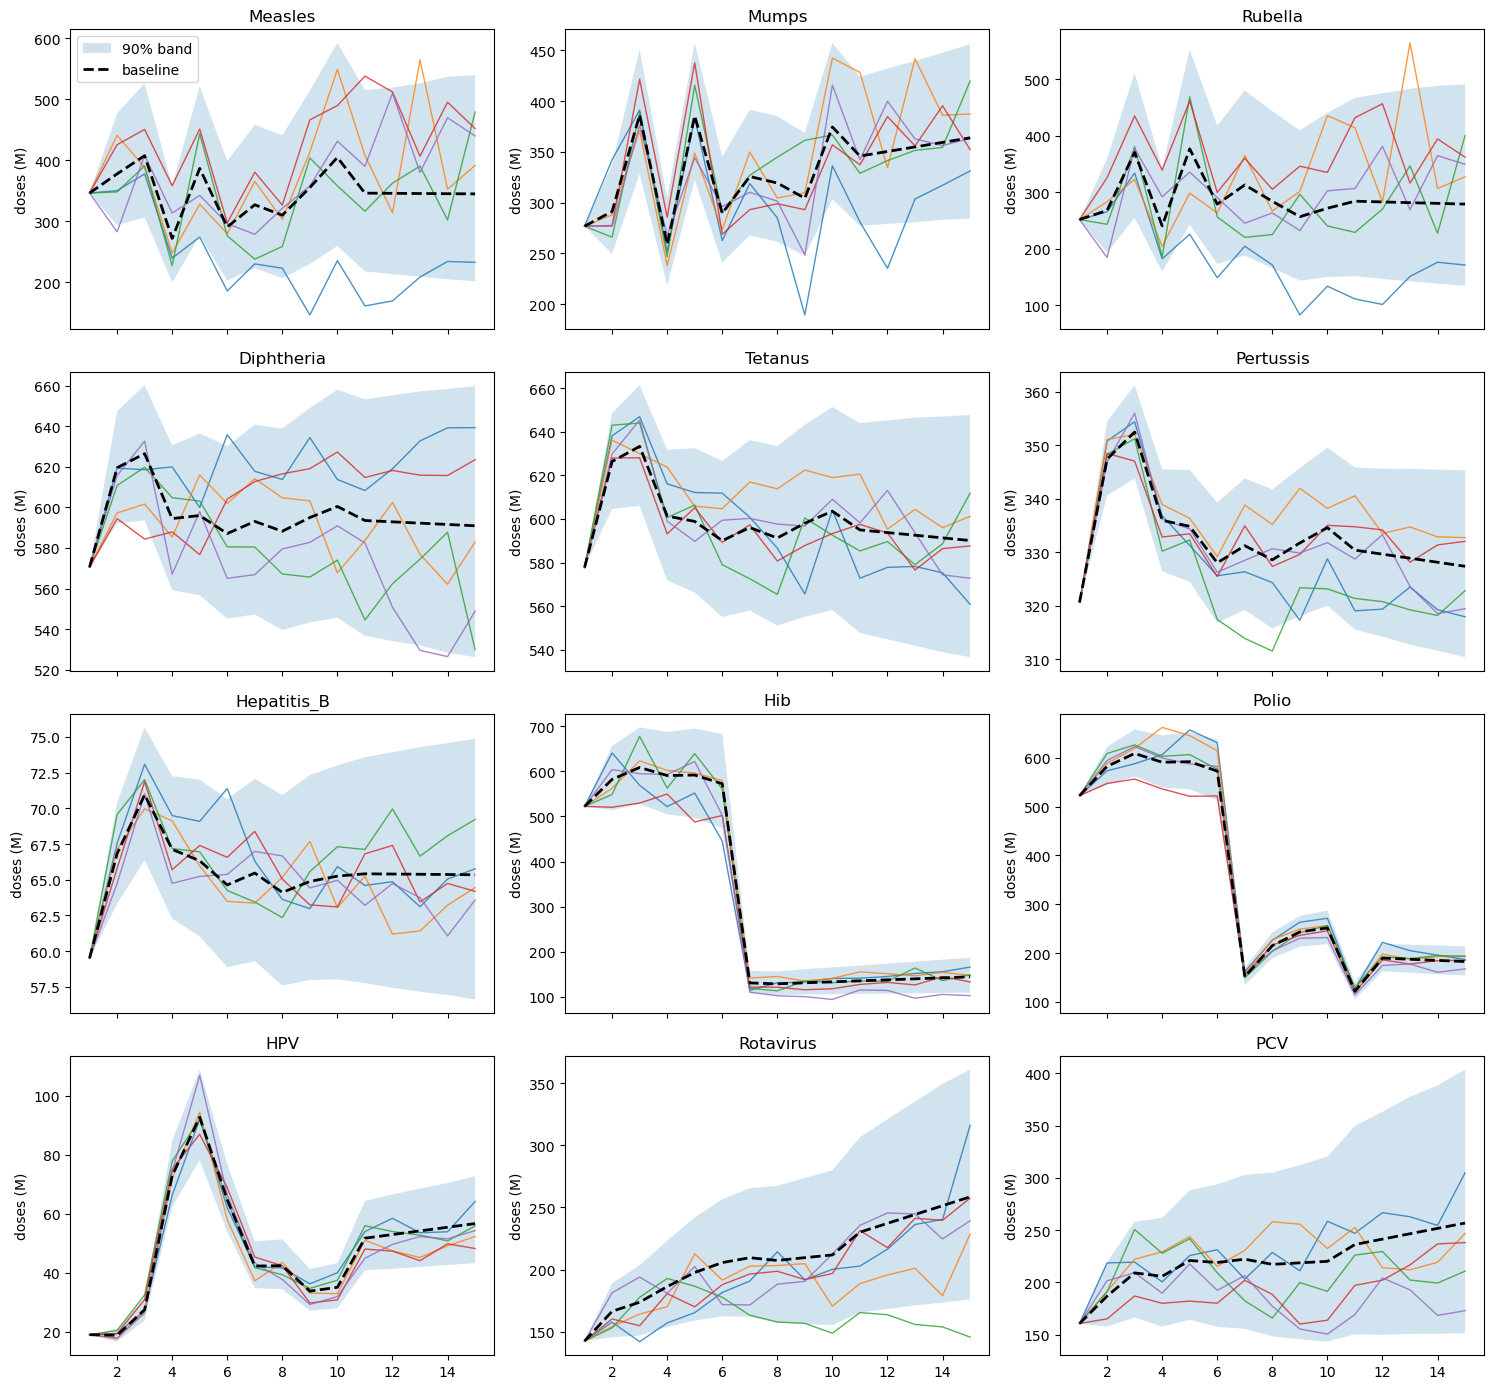

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14), sharex=True)
years_axis = baseline.columns
for ax, (i, a) in zip(axes.flat, enumerate(FORECAST_ANTIGENS)):
    lo, hi = np.percentile(check[:, i, :], [5, 95], axis=0)
    ax.fill_between(years_axis, lo / 1e6, hi / 1e6, alpha=0.2, label="90% band")
    for k in range(N_DEMAND_SCENARIOS):
        ax.plot(years_axis, draws[k, i, :] / 1e6, lw=1, alpha=0.8)
    ax.plot(years_axis, baseline.loc[a] / 1e6, "k--", lw=2, label="baseline")
    ax.set_title(a)
    ax.set_ylabel("doses (M)")
axes.flat[0].legend()
plt.tight_layout()
plt.show()

### 2f: Save the demand draws (`antigen_demand_80_20_5_scenarios` format)

In [12]:
rows = []
for k in range(N_DEMAND_SCENARIOS):
    for i, a in enumerate(FORECAST_ANTIGENS):
        demands = "[" + ", ".join(str(int(round(x))) for x in draws[k, i, :]) + "]"
        rows.append({"antigen": a, "demands": demands, "prob": 1.0 / N_DEMAND_SCENARIOS, "demand_SID": k + 1})

forecast_df = pd.DataFrame(rows).sort_values(["antigen", "demand_SID"]).reset_index(drop=True)
forecast_df.to_csv(DEMAND_FORECAST_FILE, index=False)
print(f"Saved {N_DEMAND_SCENARIOS} draws x {len(FORECAST_ANTIGENS)} antigens to {DEMAND_FORECAST_FILE}")
forecast_df.head(N_DEMAND_SCENARIOS * 2)

Saved 5 draws x 12 antigens to data/antigen_demand_forecast_scenario.csv


,antigen,demands,prob,demand_SID
0,Diphtheria,"[570550152, 619331506, 618567496, 619970928, 5...",0.2,1
1,Diphtheria,"[570550152, 597271126, 601632445, 585414687, 6...",0.2,2
2,Diphtheria,"[570550152, 610761264, 619795507, 604814750, 6...",0.2,3
3,Diphtheria,"[570550152, 594458600, 584376321, 587928464, 5...",0.2,4
4,Diphtheria,"[570550152, 615661031, 632669243, 567095804, 5...",0.2,5
5,HPV,"[18988210, 19315184, 27116889, 66197749, 91936...",0.2,1
6,HPV,"[18988210, 17515501, 27176061, 72044140, 94381...",0.2,2
7,HPV,"[18988210, 20418855, 32445725, 77756888, 92060...",0.2,3
8,HPV,"[18988210, 19390717, 30879231, 75094238, 86898...",0.2,4
9,HPV,"[18988210, 17844949, 26295293, 74192016, 10681...",0.2,5


## Step 3: Create demand-capacity scenario pairs

In [13]:
# Load the demand forecast draws (Step 2) in the pairing format
demand_scenarios_df = pd.read_csv(
    DEMAND_FORECAST_FILE,
    converters={"demands": pd.eval},
).rename(columns={"demands": "demand", "prob": "probability"})

demand_scenarios_df2 = demand_scenarios_df[demand_scenarios_df['antigen'].isin(ANTIGENS)]

capacity_scenarios_df = capacity_scenarios

# Function to generate pairs: full cross product of demand x capacity scenarios
def generate_pairs(demand: pd.DataFrame, capacity: pd.DataFrame, verbose: bool = True):
    demand_dict = demand.drop_duplicates(subset=["demand_SID"]).set_index("demand_SID")["probability"].to_dict()
    capacity_dict = capacity.drop_duplicates(subset=["capacity_scenario"]).set_index("capacity_scenario")["capacity_scenario_probability"].to_dict()

    if verbose:
        print(f"Unique demand scenarios: {list(demand_dict.keys())}")
        print(f"Unique capacity scenarios: {list(capacity_dict.keys())}")

    pairs = []
    pair_dfs = []
    prob_dict = {}
    pair_idx = 1

    for selected_capacity, selected_prob_capacity in capacity_dict.items():
        for selected_demand, selected_prob_demand in demand_dict.items():
            # Combine the probabilities (demand and capacity independent)
            prob_dict[pair_idx] = selected_prob_demand * selected_prob_capacity

            # Get the selected demand and capacity scenarios
            selected_demand_df = demand[demand["demand_SID"] == selected_demand].copy()
            selected_demand_df["type"] = "antigen"
            selected_demand_df.drop(columns=["probability", "demand_SID"], inplace=True)
            selected_demand_df.rename(columns={"antigen": "unit", "demand": "values"}, inplace=True)

            selected_capacity_df = capacity[capacity["capacity_scenario"] == selected_capacity].copy()
            selected_capacity_df["type"] = "manufacturer"
            selected_capacity_df.drop(columns=["capacity_scenario_probability", "capacity_scenario"], inplace=True)
            selected_capacity_df.rename(columns={"manufacturer": "unit", "capacity": "values"}, inplace=True)

            pair_df = pd.concat([selected_demand_df, selected_capacity_df])

            # Add additional information
            pair_df["pair_idx"] = pair_idx
            pair_df["pair"] = f"Demand: {selected_demand} - Capacity: {selected_capacity}"
            pair_dfs.append(pair_df)
            pairs.append((selected_demand, selected_capacity))
            pair_idx += 1

    pair_df = pd.concat(pair_dfs, ignore_index=True)

    # Scale the probabilities so they sum up to 1
    total_sum = sum(prob_dict.values())
    scaled_probabilities = {k: v / total_sum for k, v in prob_dict.items()}
    pair_df["pair_probability"] = pair_df["pair_idx"].map(scaled_probabilities)

    if verbose:
        print(f"{len(demand_dict)} demand x {len(capacity_dict)} capacity = {len(pairs)} scenario pairs")

    return pairs, pair_df

# Generate pairs
scenario_pairs, pair_df = generate_pairs(demand_scenarios_df2, capacity_scenarios_df, verbose=True)

# Export to json and csv
pair_df.to_json("data/pair_demand_capacity_15YR_stoch.json", orient="records", lines=True)
pair_df.to_csv("data/pair_demand_capacity_15YR_stoch.csv", index=False)

# Display the DataFrame
pair_df

Unique demand scenarios: [1, 2, 3, 4, 5]
Unique capacity scenarios: ['base_capacity', 'IPV_Shortage', 'pandemic', 'funding_delay', 'innacurate_forecast', 'supply_chain', 'other']
5 demand x 7 capacity = 35 scenario pairs


,unit,values,type,pair_idx,pair,pair_probability
0,Diphtheria,"[570550152, 619331506, 618567496, 619970928, 5...",antigen,1,Demand: 1 - Capacity: base_capacity,0.16836
1,HPV,"[18988210, 19315184, 27116889, 66197749, 91936...",antigen,1,Demand: 1 - Capacity: base_capacity,0.16836
2,Hepatitis_B,"[59502552, 67551191, 73086833, 69492867, 69088...",antigen,1,Demand: 1 - Capacity: base_capacity,0.16836
3,Hib,"[522182009, 640902248, 569130034, 521821861, 5...",antigen,1,Demand: 1 - Capacity: base_capacity,0.16836
4,Measles,"[346093157, 350029519, 377506221, 239236388, 2...",antigen,1,Demand: 1 - Capacity: base_capacity,0.16836
...,...,...,...,...,...,...
940,PT_Bio,"[53364779.6951938, 65600000.0, 74700000.0, 729...",manufacturer,35,Demand: 5 - Capacity: other,0.00550
941,Panacea_Biotec,"[96900000.0, 110200000.0, 111600000.0, 1053000...",manufacturer,35,Demand: 5 - Capacity: other,0.00550
942,Pfizer,"[55510000.0, 63349999.99999999, 65799999.99999...",manufacturer,35,Demand: 5 - Capacity: other,0.00550
943,Sanofi,"[9730000.0, 10640000.0, 10402228.06457212, 110...",manufacturer,35,Demand: 5 - Capacity: other,0.00550


In [14]:
pair_df['unit'].unique()

array(['Diphtheria', 'HPV', 'Hepatitis_B', 'Hib', 'Measles', 'Mumps', 'PCV',
       'Pertussis', 'Polio', 'Rotavirus', 'Rubella', 'Tetanus',
       'Serum_Institute', 'GSK', 'Biological_E', 'Haffkine_Bio',
       'Panacea_Biotec', 'Sanofi', 'LG_Chem', 'Bharat_Biotech', 'Pfizer',
       'BB_NCIPD', 'Merck_Sharp', 'PT_Bio', 'China_National', 'Bilthoven',
       'AJ_Vaccines'], dtype=object)

In [15]:
pair_df.groupby('unit').count()

,values,type,pair_idx,pair,pair_probability
unit,,,,,
AJ_Vaccines,35,35,35,35,35
BB_NCIPD,35,35,35,35,35
Bharat_Biotech,35,35,35,35,35
Bilthoven,35,35,35,35,35
Biological_E,35,35,35,35,35
China_National,35,35,35,35,35
Diphtheria,35,35,35,35,35
GSK,35,35,35,35,35
HPV,35,35,35,35,35


## Step 4: Build the scenario pair dictionary

Reads back the pair CSV written in Step 3, so the JSON is built exactly as before.

In [16]:
# Load the CSV file
file_path = 'data/pair_demand_capacity_15YR_stoch.csv'
data = pd.read_csv(file_path)

# Initialize dictionary for scenario pairs
expanded_scenario_pairs = {}

# Iterate over the rows and populate the dictionary
for _, row in data.iterrows():
    pair_idx = row['pair_idx']
    category = 'demand' if row['type'] == 'antigen' else 'capacity'

    # Remove brackets, split space-separated string, and convert to floats
    values_str = row['values'].strip('[]')
    # values = list(map(float, values_str.split()))
    values_str = row['values'].strip('[]').replace(',', '')
    values = list(map(float, values_str.split()))
    unit = row['unit']

    expanded_scenario_pairs.setdefault(pair_idx, {'demand': {}, 'capacity': {}})

    for i, value in enumerate(values, 1):
        expanded_scenario_pairs[pair_idx][category].setdefault(i, {})[unit] = value

expanded_scenario_pairs.keys()

dict_keys([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35])

In [17]:
# Define the file path for the JSON output
json_output_path = 'data/scenario_pairs_new_15YR_stoch.json'

# Write the dictionary to a JSON file
with open(json_output_path, 'w') as json_file:
    json.dump(expanded_scenario_pairs, json_file)

json_output_path

'data/scenario_pairs_new_15YR_stoch.json'

## Step 5: Save the scenario pair probabilities

In [18]:
# Load the CSV file into a DataFrame
file_path = 'data/pair_demand_capacity_15YR_stoch.csv'
df = pd.read_csv(file_path)

# Create the dictionary with scenarios and their probabilities
scenarios_probabilities = df[['pair_idx', 'pair_probability']].drop_duplicates().set_index('pair_idx')['pair_probability'].to_dict()

json_file_path = 'data/scenario_pair_probabilities_new_15YR_stoch.json'

# Write the dictionary to a JSON file
with open(json_file_path, 'w') as json_file:
    json.dump(scenarios_probabilities, json_file, indent=4)

print(f"Scenarios probabilities have been saved to {json_file_path}")

Scenarios probabilities have been saved to data/scenario_pair_probabilities_new_15YR_stoch.json


In [19]:
# Copy the model input files to the model's data folder
for f in ["scenario_pairs_new_15YR_stoch.json", "scenario_pair_probabilities_new_15YR_stoch.json"]:
    shutil.copy(os.path.join("data", f), os.path.join(MODEL_DATA_DIR, f))
    print(f"Copied {f} -> {MODEL_DATA_DIR}")

print(f"{len(scenarios_probabilities)} scenario pairs = {capacity_scenarios['capacity_scenario'].nunique()} capacity x {N_DEMAND_SCENARIOS} demand")

Copied scenario_pairs_new_15YR_stoch.json -> ../data
Copied scenario_pair_probabilities_new_15YR_stoch.json -> ../data
35 scenario pairs = 7 capacity x 5 demand
